In [71]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Sampler, random_split
import time
import random
import math
from collections import deque
import numpy as np
import scipy
import ot
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [ ]:
### Hungarian Matching
def hungarian_matching(mtx_cost):
    indices = scipy.optimize.linear_sum_assignment(mtx_cost)
    permutation = np.zeros(mtx_cost.shape)
    permutation[indices] = 1
    
    return permutation

### Sinkhorn normalization
def my_sinkhorn_norm(mtx_cost, temp=0.01, n_iter=20):
    # M is the cost matrix (= "logits" / scores)
    # M should ideally be squared for this operation to make sens
    # a kernel in log space is used to do the calculations and is only exponentiated at the end to get probabilities!
    # minus because smaller cost should yield higher probability...
    
    mtx_kernel = - mtx_cost / temp
    
    for _ in range(n_iter):
        mtx_kernel = mtx_kernel - scipy.special.logsumexp(mtx_kernel, axis=1, keepdims=True)
        mtx_kernel = mtx_kernel - scipy.special.logsumexp(mtx_kernel, axis=0, keepdims=True)
    
    return np.exp(mtx_kernel)

def torch_sinkhorn(mtx_cost, temp=0.01, n_iter=20):
    mtx_kernel = -mtx_cost / temp
    mtx_kernel = torch.tensor(mtx_kernel)
    
    for _ in range(n_iter):
        mtx_kernel = mtx_kernel - torch.logsumexp(mtx_kernel, dim=1, keepdim=True)  
        mtx_kernel = mtx_kernel - torch.logsumexp(mtx_kernel, dim=0, keepdim=True)
    
    return torch.exp(mtx_kernel)

## Gumbel Sinkhorn Sampling
def sample_gumbel(shape, eps=1e-20):
    U = np.random.uniform(size=(shape[0], shape[1]))
    return -np.log(eps - np.log(U + eps))

def sinkhorn_gumbel(mtx_cost, temp=0.01, n_iter=20):
    # minus before cost mtx can control whether to maximize or minimize w.r.t. cost!
    mtx_kernel = (- mtx_cost + 0.01*np.random.gumbel(size=mtx_cost.shape)) / temp
    
    for _ in range(n_iter):
        mtx_kernel = mtx_kernel - scipy.special.logsumexp(mtx_kernel, axis=1, keepdims=True)
        mtx_kernel = mtx_kernel - scipy.special.logsumexp(mtx_kernel, axis=0, keepdims=True)
    
    return np.exp(mtx_kernel)

In [ ]:
cost = np.random.rand(5, 5)
display("cost mtx: ", cost.round(decimals=2))
display("hungarian match ", hungarian_matching(cost).astype(np.int32))
display("my normal sinkhorn", my_sinkhorn_norm(cost, temp=0.01, n_iter=20).round(decimals=2))

In [157]:
test_label = np.array([1, 1, 1, 0, 0])[None, :]

test_conf  = np.random.rand(5, 1)

test_euclid = np.zeros((5, 5))
test_euclid[:, 0:3] = np.random.rand(5, 3) * (2*np.sqrt(2))

print("inputs ------------------------------")
display(test_conf.round(decimals=2), test_label)
display(test_euclid.round(decimals=2))

temp = 0.1
pseudomax = scipy.special.softmax(test_euclid.reshape(-1)/temp)
pseudomax = np.sum(pseudomax.reshape(test_euclid.shape) * test_euclid)

test_mtx = (test_conf * test_euclid) + pseudomax * ((1-test_conf) * np.ones(test_euclid.shape) * test_label)

permutation = my_sinkhorn_norm(test_mtx, temp=0.1, n_iter=100)

print("outputs ------------------------------")
display("masked euclid", test_mtx.round(decimals=2))
display("permutation", permutation.round(decimals=2))


inputs ------------------------------


array([[0.52],
       [0.72],
       [0.32],
       [0.96],
       [0.12]])

array([[1, 1, 1, 0, 0]])

array([[2.74, 0.83, 0.04, 0.  , 0.  ],
       [0.33, 1.86, 0.46, 0.  , 0.  ],
       [0.31, 0.3 , 0.13, 0.  , 0.  ],
       [2.28, 1.65, 1.92, 0.  , 0.  ],
       [0.75, 1.02, 0.54, 0.  , 0.  ]])

outputs ------------------------------


'masked euclid'

array([[2.73, 1.73, 1.32, 0.  , 0.  ],
       [1.01, 2.1 , 1.1 , 0.  , 0.  ],
       [1.95, 1.95, 1.9 , 0.  , 0.  ],
       [2.3 , 1.69, 1.95, 0.  , 0.  ],
       [2.48, 2.52, 2.46, 0.  , 0.  ]])

'permutation'

array([[0.  , 0.1 , 0.86, 0.02, 0.02],
       [0.91, 0.  , 0.09, 0.  , 0.  ],
       [0.09, 0.16, 0.04, 0.35, 0.35],
       [0.  , 0.74, 0.01, 0.12, 0.12],
       [0.  , 0.  , 0.  , 0.5 , 0.5 ]])

In [179]:
test_mtx = np.zeros((5, 5))
test_mtx = test_mtx

display(test_mtx)

display(my_sinkhorn_norm(test_mtx, temp=0.1, n_iter=100))

aaa = torch.tensor([0, 0, 0, 0]).float()
aaa = torch.nn.functional.softmax(aaa, dim=0)
display(aaa)

print(0/(0+0.00000001))

array([[0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.]])

array([[0.2, 0.2, 0.2, 0.2, 0.2],
       [0.2, 0.2, 0.2, 0.2, 0.2],
       [0.2, 0.2, 0.2, 0.2, 0.2],
       [0.2, 0.2, 0.2, 0.2, 0.2],
       [0.2, 0.2, 0.2, 0.2, 0.2]])

tensor([0.2500, 0.2500, 0.2500, 0.2500])

0.0


average distance: 1.0433384064311948


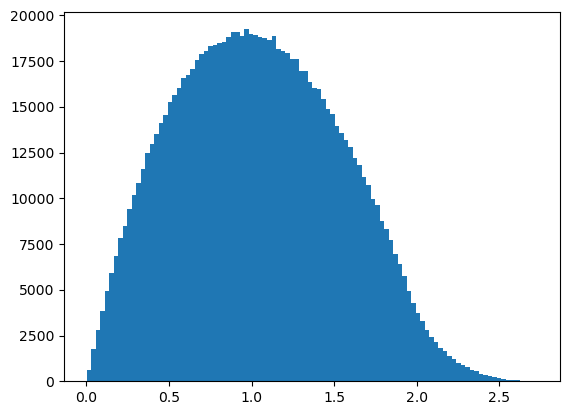

In [75]:
n_points = 1000000

leaks = 2*np.random.rand(n_points, 2) - 1
labels = 2*np.random.rand(n_points, 2) - 1

dist = np.linalg.norm(leaks-labels, ord=2, axis=1, keepdims=True)

print(f"average distance: {np.average(dist)}")

_ = plt.hist(dist, bins=100)

#### Experiments

In [ ]:
### Sinkhorn normalization

def incomplete_sinkhorn_log_numpy(M, temp=0.01, n_iter=20):
    n, m = M.shape
    phi = -M / temp  # Log of the initial kernel

    # Initialize log scaling vectors (u and v in log-space)
    log_u = np.zeros(n)
    log_v = np.zeros(m)
    
    # Iteratively normalize rows and columns
    for _ in range(n_iter):
        # Update log_u
        log_u = -np.log(np.sum(np.exp(phi + log_v.reshape(1, -1)), axis=1))
        
        # Update log_v
        log_v = -np.log(np.sum(np.exp(phi.T + log_u.reshape(1, -1)), axis=1))
    
    # Compute the transport matrix in log space
    T_log = phi + log_u[:, np.newaxis] + log_v[np.newaxis, :]
    T = np.exp(T_log)  # Exponentiate to get final transport plan
    
    return T
  
def torch_sinkhorn(mtx_cost, temp=0.01, n_iter=20):
    mtx_kernel = -mtx_cost / temp
    
    for _ in range(n_iter):
        mtx_kernel = mtx_kernel - torch.logsumexp(mtx_kernel, dim=1, keepdim=True)  
        mtx_kernel = mtx_kernel - torch.logsumexp(mtx_kernel, dim=0, keepdim=True)
    
    return torch.exp(mtx_kernel)
    
def my_sinkhorn_norm(mtx_cost, temp=0.01, n_iter=20):
    # M is the cost matrix (= "logits" / scores)
    # M should ideally be squared for this operation to make sens
    # a kernel in log space is used to do the calculations and is only exponentiated at the end to get probabilities!
    # minus because smaller cost should yield higher probability...
    
    mtx_kernel = - mtx_cost / temp
    
    for _ in range(n_iter):
        mtx_kernel = mtx_kernel - scipy.special.logsumexp(mtx_kernel, axis=1, keepdims=True)
        mtx_kernel = mtx_kernel - scipy.special.logsumexp(mtx_kernel, axis=0, keepdims=True)
    
    return np.exp(mtx_kernel)
    
def test_implementations(N=1000):        
    t0 = time.time()
    for _ in range(N):
        _ = my_sinkhorn_norm(cost)
    t1 = time.time()
    t_mine = (t1-t0)/N

    t0 = time.time()
    for _ in range(N):
        _ = incomplete_sinkhorn_log_numpy(cost)
    t1 = time.time()
    t_cgpt = (t1-t0)/N

    t0 = time.time()
    for _ in range(N):
        _ = torch_sinkhorn(cost_tensor)
    t1 = time.time()
    t_torch = (t1-t0)/N

    print(f"my time:    {t_mine:.5f}s")
    print(f"cgpt time:  {t_cgpt:.5f}s")
    print(f"torch time: {t_torch:.5f}")
    return


    
test_implementations() 